In [2]:
from functions import *

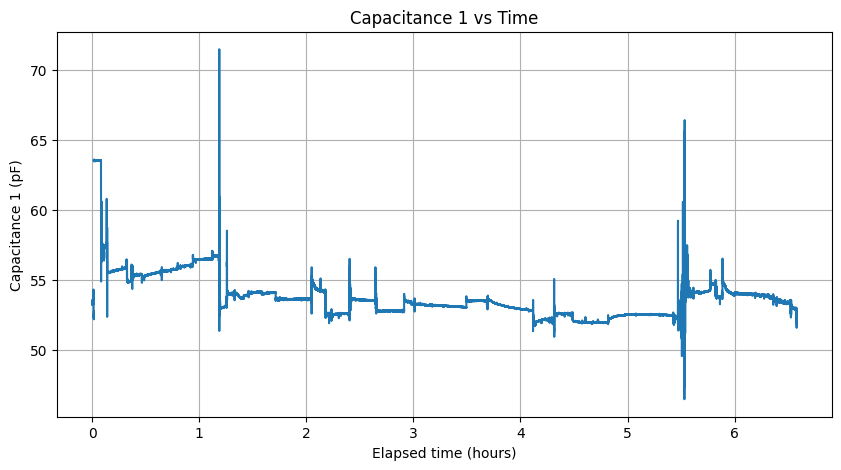

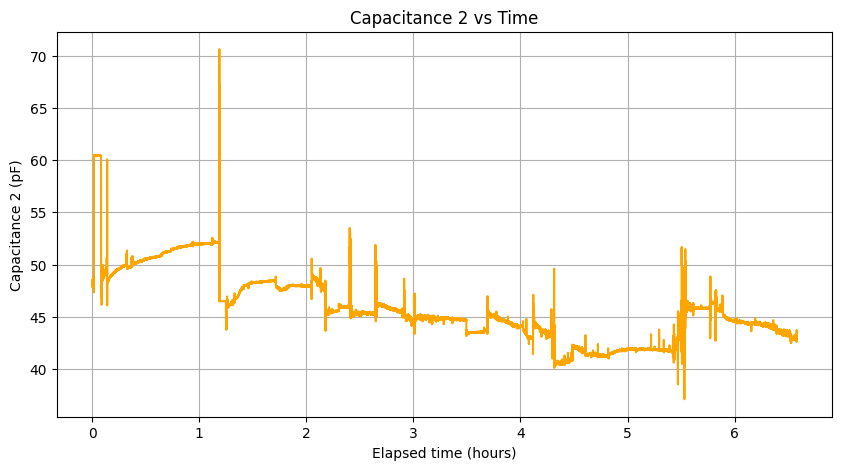

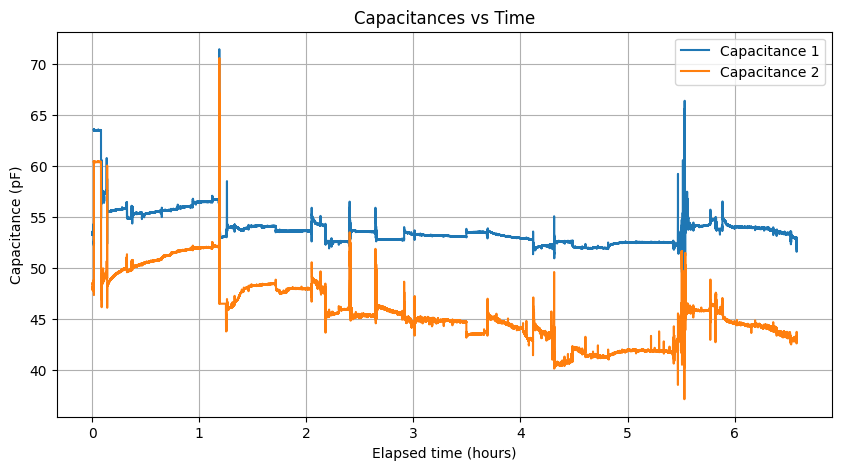

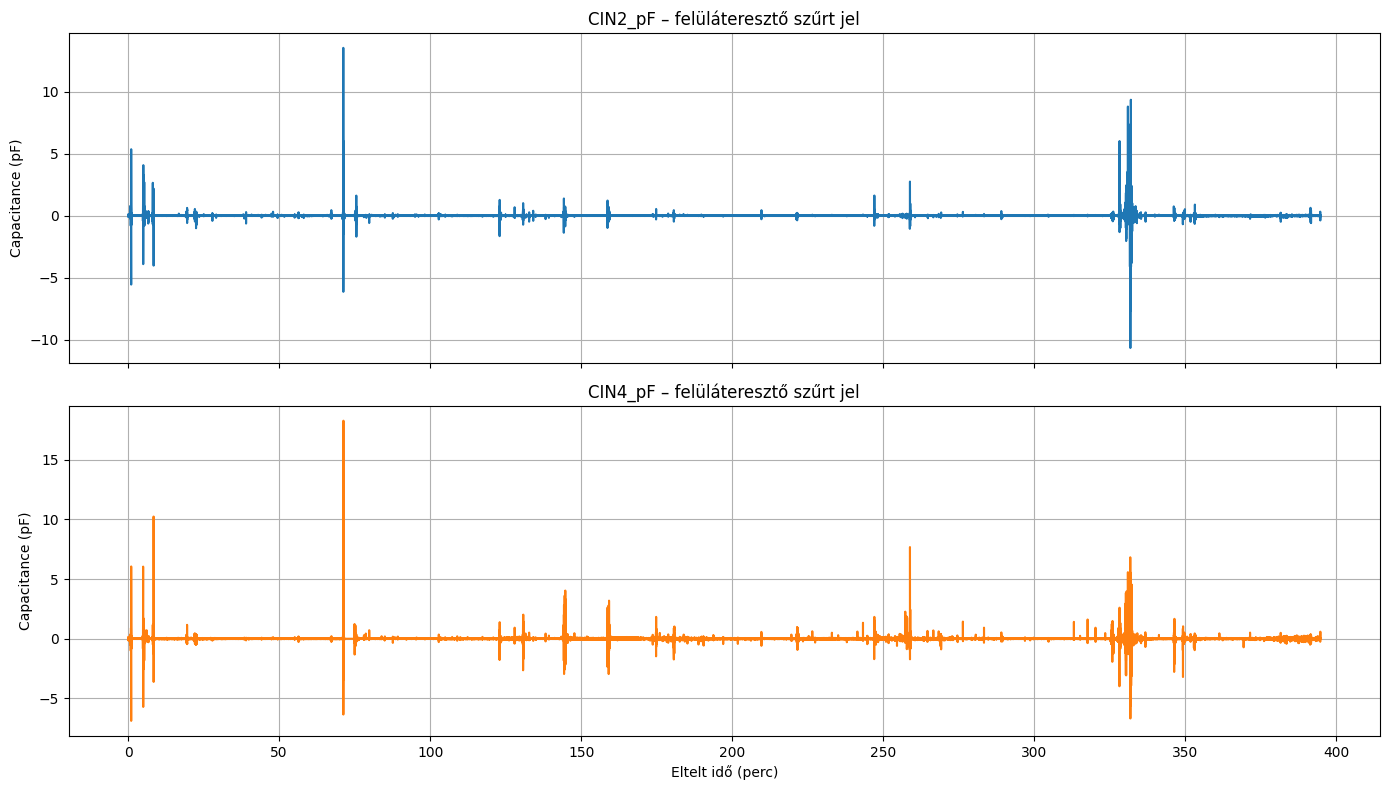

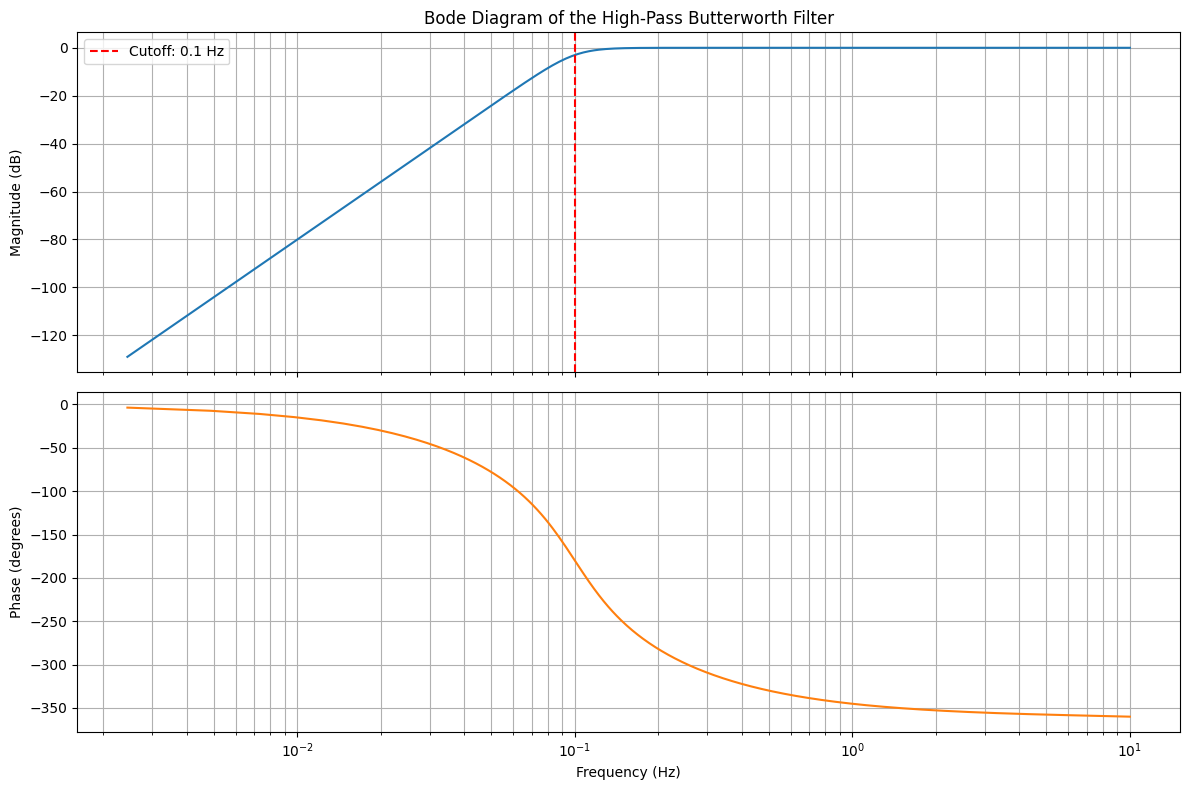

In [ ]:
first_night_path = "fdc1004_data_2026_10_15.csv"

first_night = load_data(first_night_path)
plot_raw_data(first_night)
sos = plot_filtered_data(first_night, cutoff_frequency=0.1)
plot_bode_diag(cutoff_frequency=0.1, sampling_frequency=first_night.sampling_frequency, sos=sos)


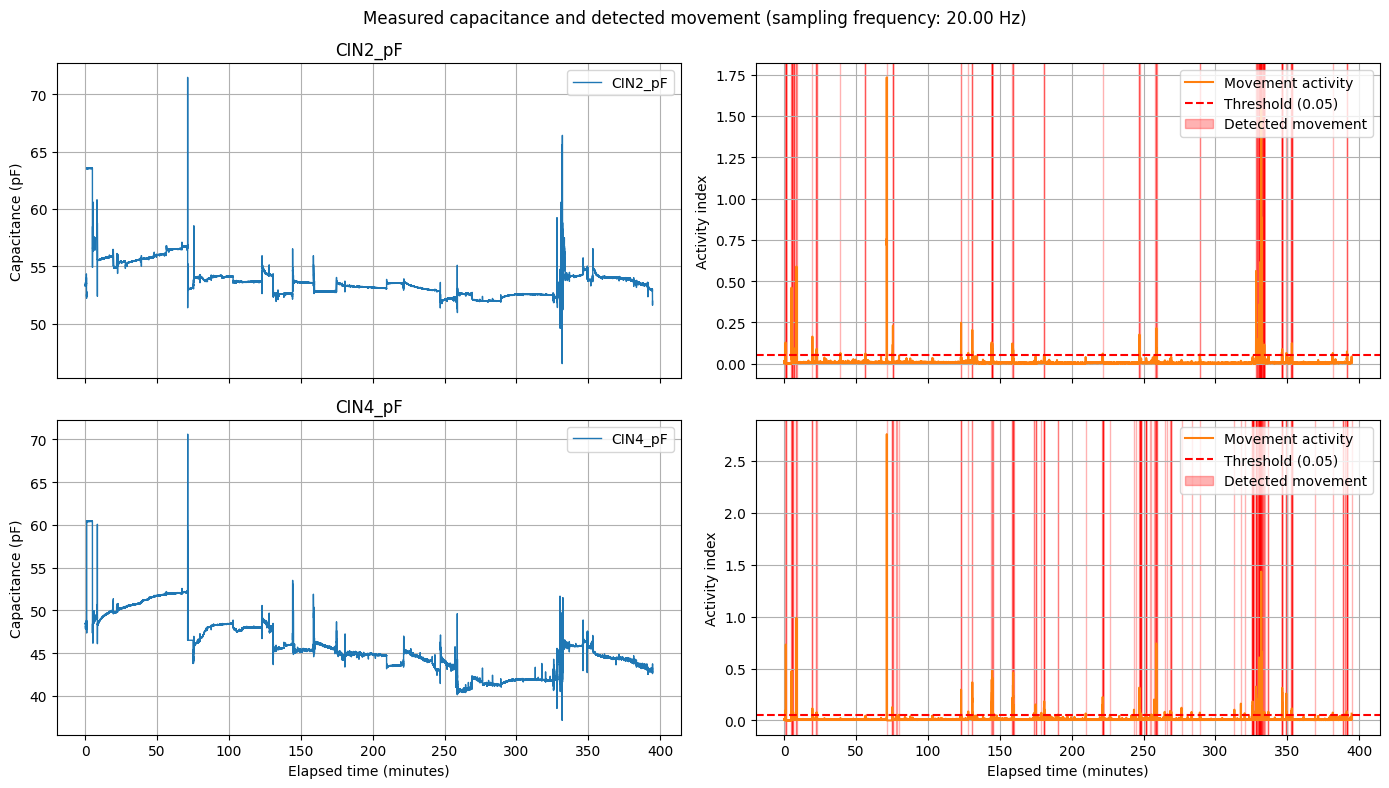

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Detection parameters
window_sec = 1.5
threshold = 0.05

# Use the data, time, and capacitance series loaded in the previous cells.
time_ms = pd.to_numeric(time, errors="coerce")
time_min = (time_ms - time_ms.iloc[0]) / 60000
sampling_frequency = 1000 / np.median(np.diff(time_ms.dropna().to_numpy()))
window_size = max(2, int(round(sampling_frequency * window_sec)))


def detect_movement(capacitance):
    signal = pd.to_numeric(capacitance, errors="coerce")
    diff_series = signal.diff().abs()
    rolling_activity = diff_series.rolling(window=window_size, center=True, min_periods=1).mean()
    movement_detected = rolling_activity > threshold
    return signal, rolling_activity, movement_detected


signals = [
    (capacitance_1_key, *detect_movement(capacitance_1)),
    (capacitance_2_key, *detect_movement(capacitance_2)),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex="col")

for row, (channel_name, signal, rolling_activity, movement_detected) in enumerate(signals):
    axes[row, 0].plot(time_min, signal, label=channel_name, color="tab:blue", linewidth=1)
    axes[row, 0].set_ylabel("Capacitance (pF)")
    axes[row, 0].set_title(channel_name)
    axes[row, 0].grid(True)
    axes[row, 0].legend(loc="upper right")

    axes[row, 1].plot(
        time_min,
        rolling_activity,
        label="Movement activity",
        color="tab:orange",
    )
    axes[row, 1].axhline(
        y=threshold,
        color="r",
        linestyle="--",
        label=f"Threshold ({threshold})",
    )
    axes[row, 1].fill_between(
        time_min,
        0,
        1,
        where=movement_detected,
        color="red",
        alpha=0.3,
        transform=axes[row, 1].get_xaxis_transform(),
        label="Detected movement",
    )
    axes[row, 1].set_ylabel("Activity index")
    axes[row, 1].grid(True)
    axes[row, 1].legend(loc="upper right")

axes[1, 0].set_xlabel("Elapsed time (minutes)")
axes[1, 1].set_xlabel("Elapsed time (minutes)")
fig.suptitle(
    f"Measured capacitance and detected movement "
    f"(sampling frequency: {sampling_frequency:.2f} Hz)"
)
plt.tight_layout()
plt.show()

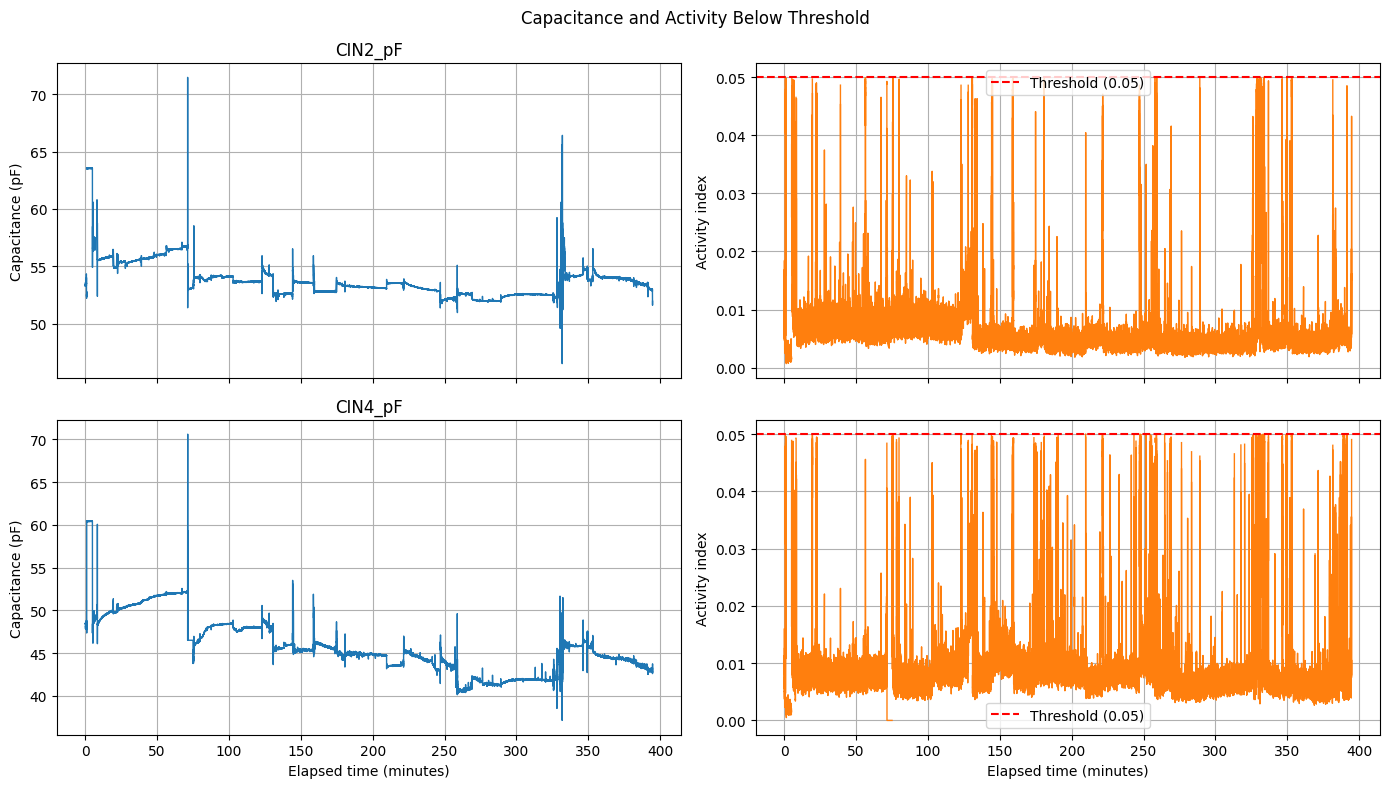

In [33]:
# Plot capacitance and activity while omitting activity values above the threshold
fig_filtered, axes_filtered = plt.subplots(2, 2, figsize=(14, 8), sharex="col")

for row, (channel_name, signal_values, activity_values, _) in enumerate(signals):
    activity_below_threshold = activity_values.where(activity_values <= threshold)

    axes_filtered[row, 0].plot(
        time_min,
        signal_values,
        color="tab:blue",
        linewidth=1,
    )
    axes_filtered[row, 0].set_ylabel("Capacitance (pF)")
    axes_filtered[row, 0].set_title(channel_name)
    axes_filtered[row, 0].grid(True)

    axes_filtered[row, 1].plot(
        time_min,
        activity_below_threshold,
        color="tab:orange",
        linewidth=1,
    )
    axes_filtered[row, 1].axhline(
        threshold,
        color="red",
        linestyle="--",
        label=f"Threshold ({threshold})",
    )
    axes_filtered[row, 1].set_ylabel("Activity index")
    axes_filtered[row, 1].grid(True)
    axes_filtered[row, 1].legend()

axes_filtered[1, 0].set_xlabel("Elapsed time (minutes)")
axes_filtered[1, 1].set_xlabel("Elapsed time (minutes)")

fig_filtered.suptitle("Capacitance and Activity Below Threshold")
plt.tight_layout()
plt.show()

# Bálint első mérései

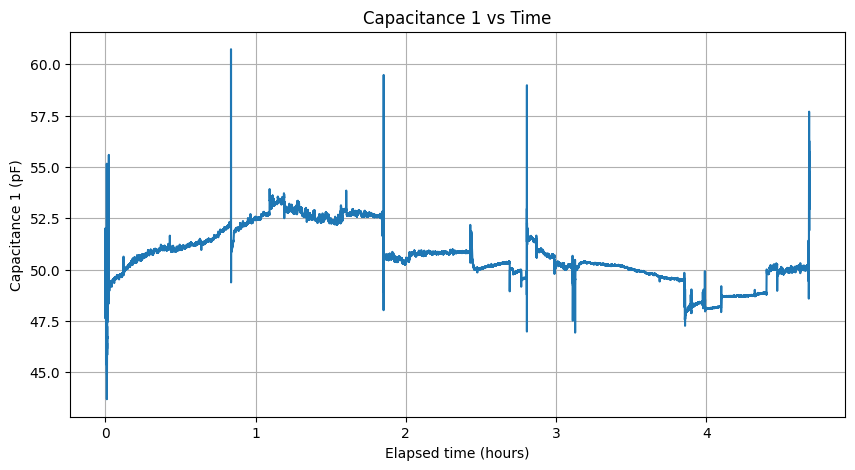

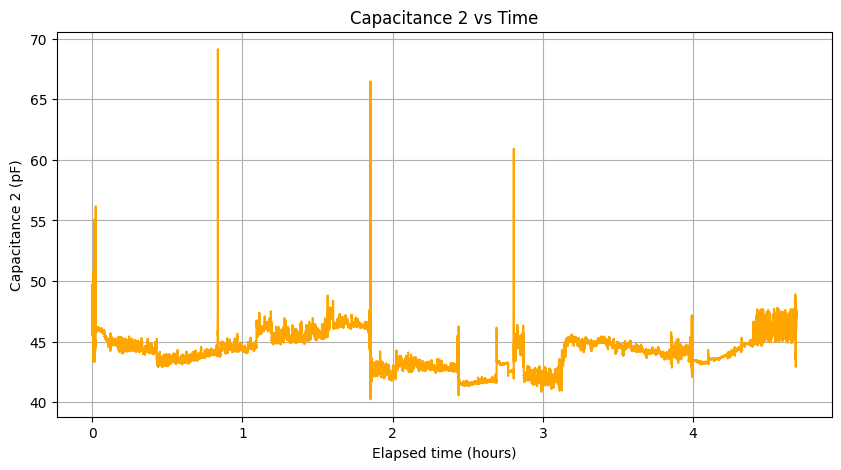

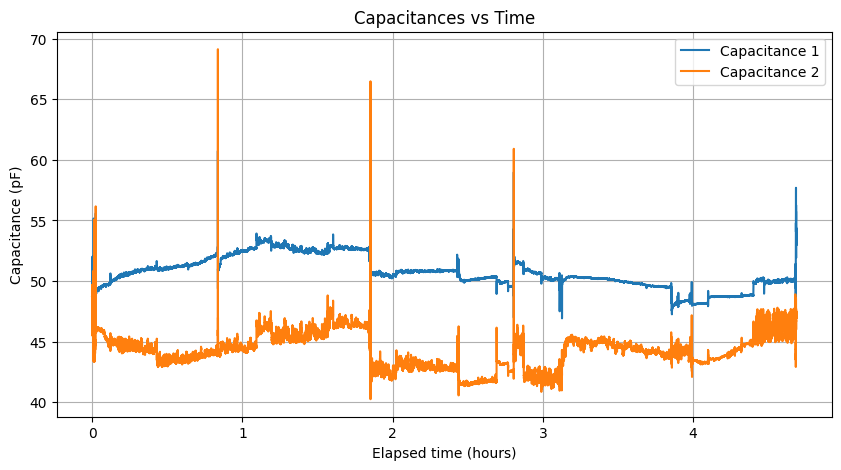

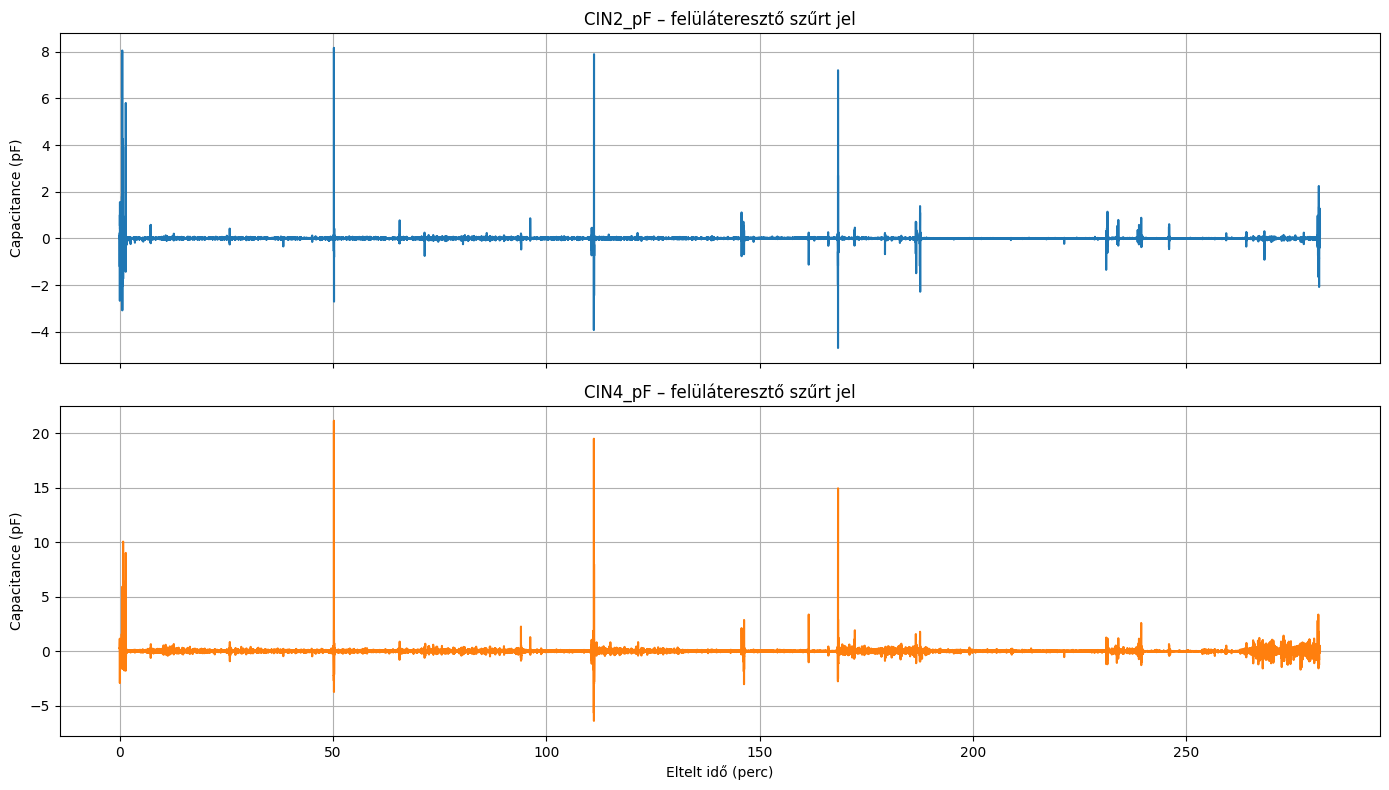

In [3]:
Balint_measurement_path = "fdc1004_data_2026_08_18.csv"

Balint_measurement = load_data(Balint_measurement_path)
plot_raw_data(Balint_measurement)
sos = plot_filtered_data(Balint_measurement, cutoff_frequency=0.1)

# Maszk tesztek

Szorítóteszt


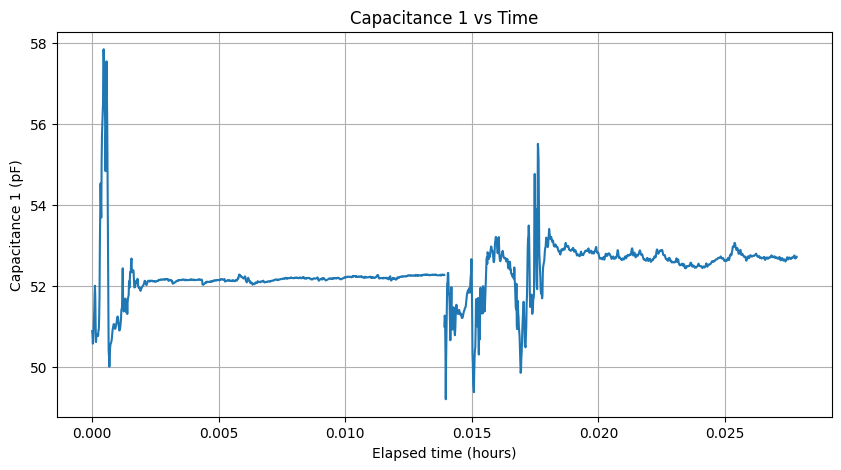

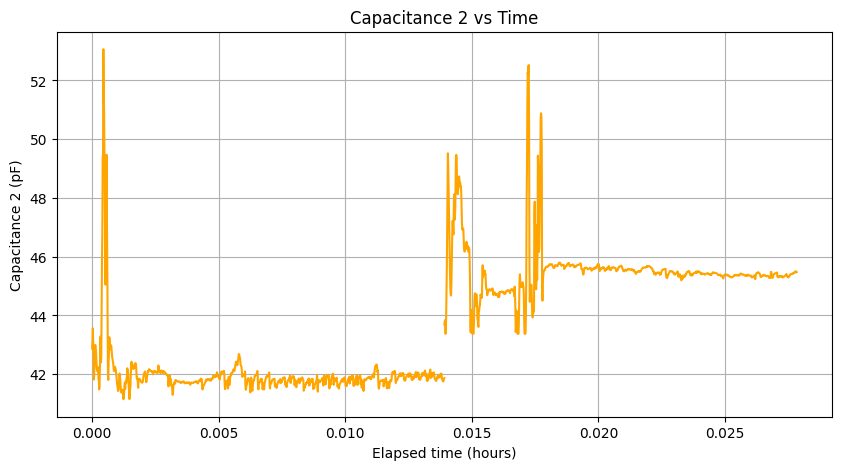

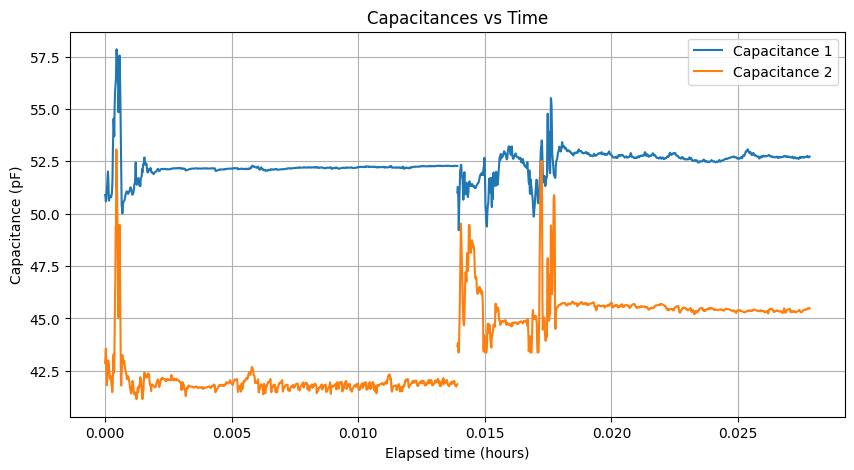

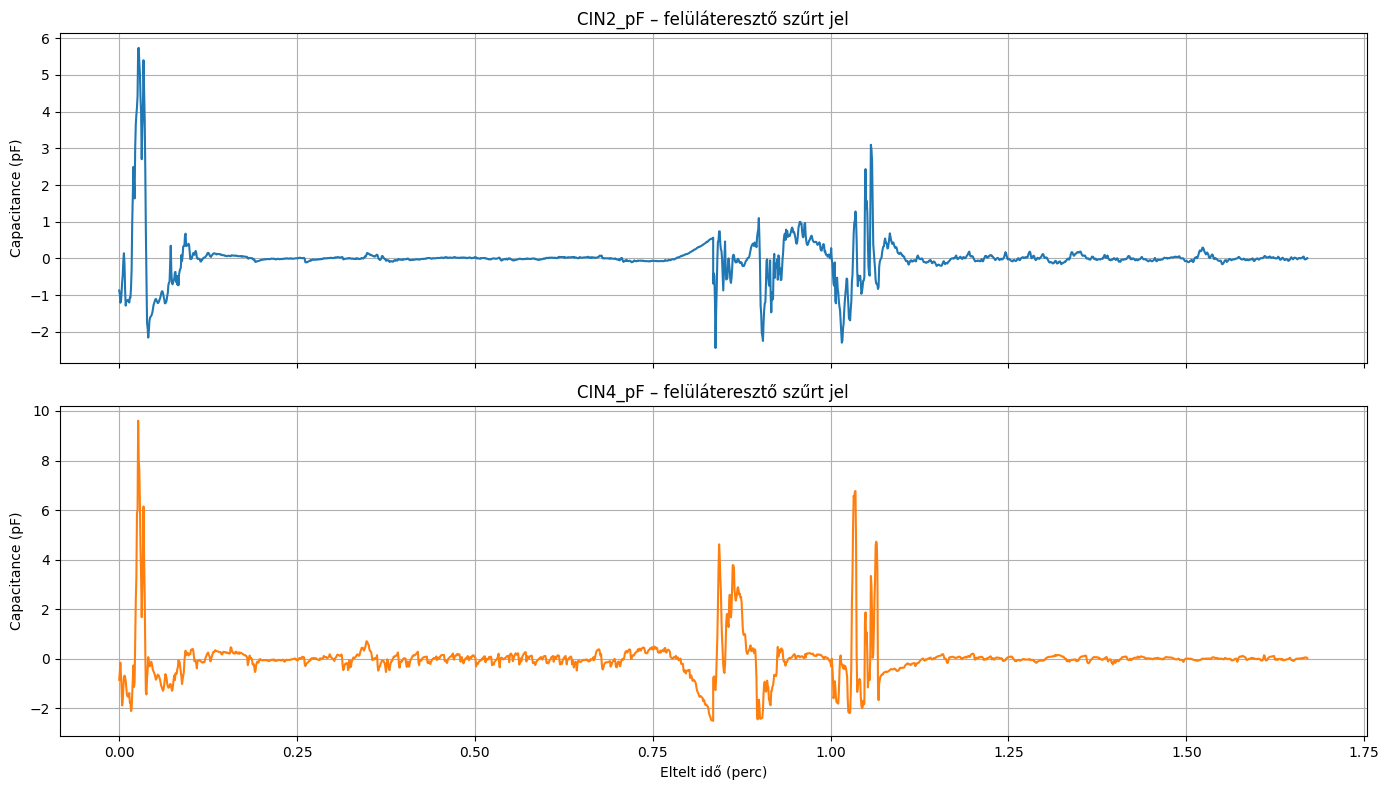

Visszateszt


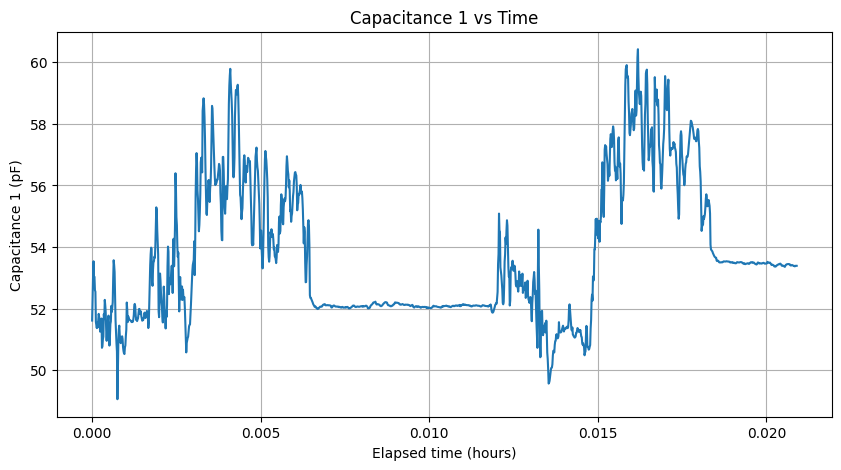

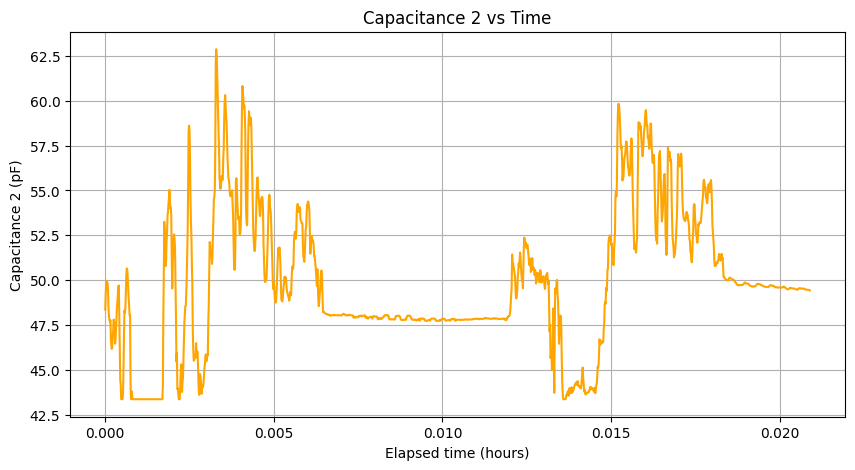

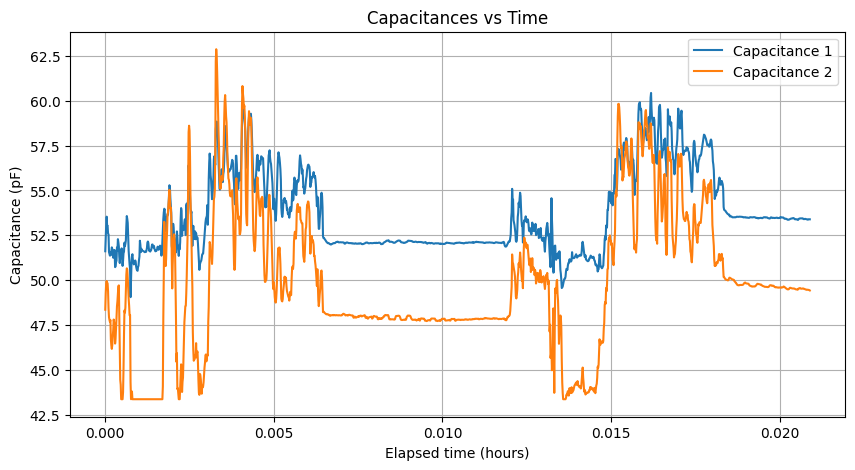

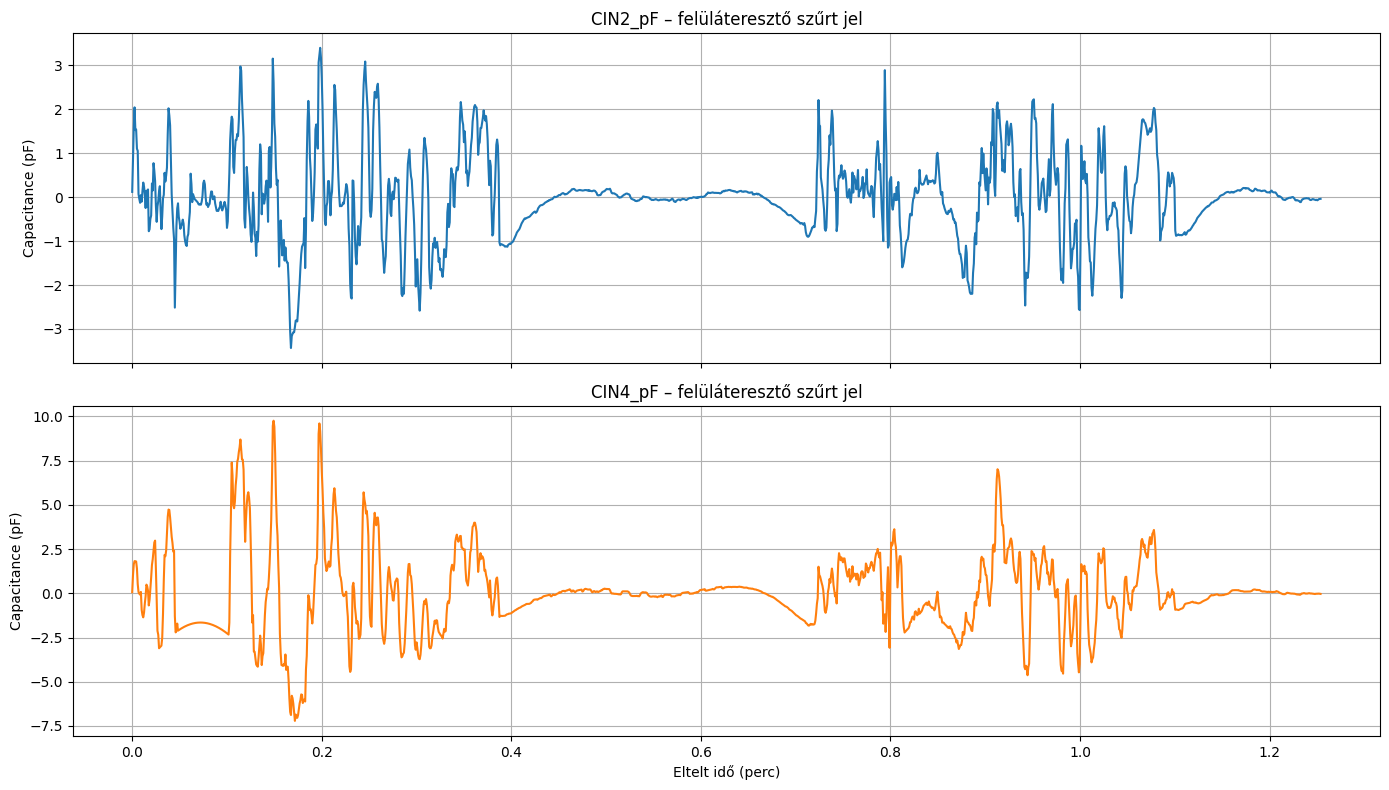

Visszateszt 2


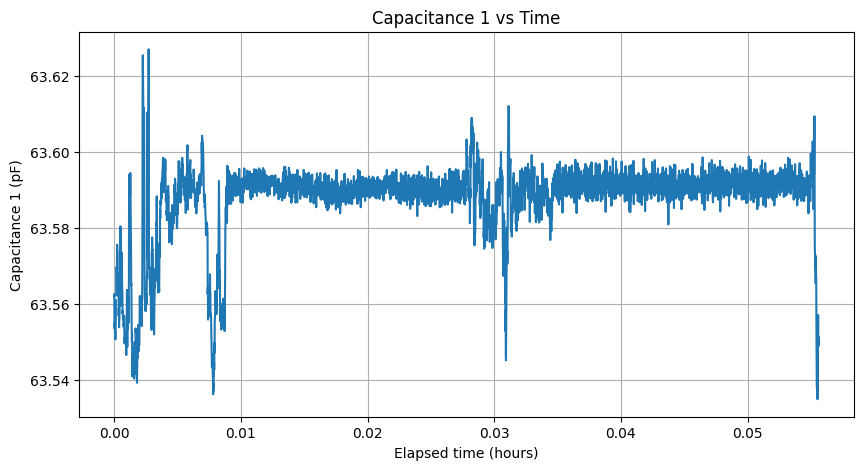

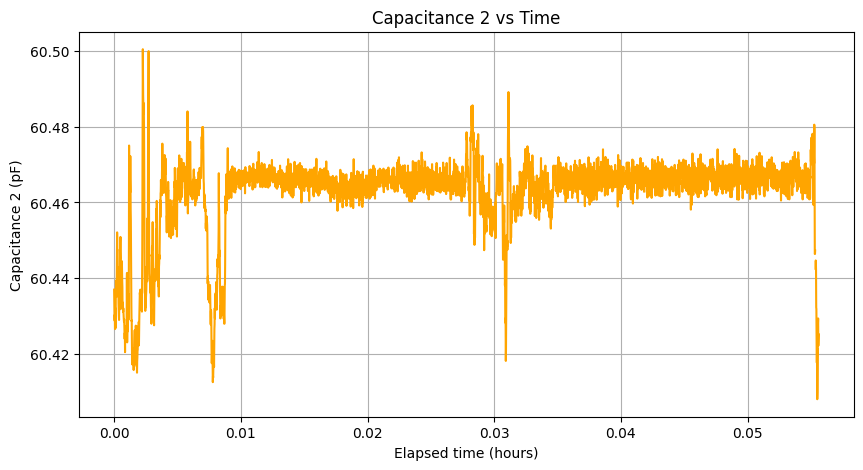

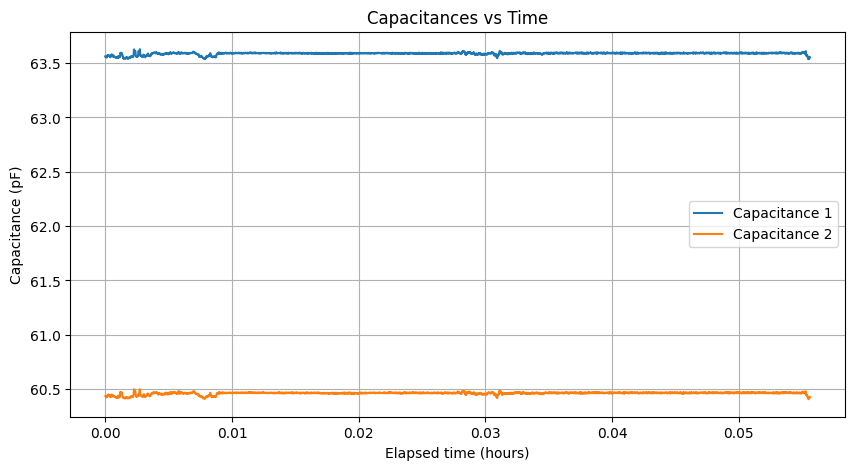

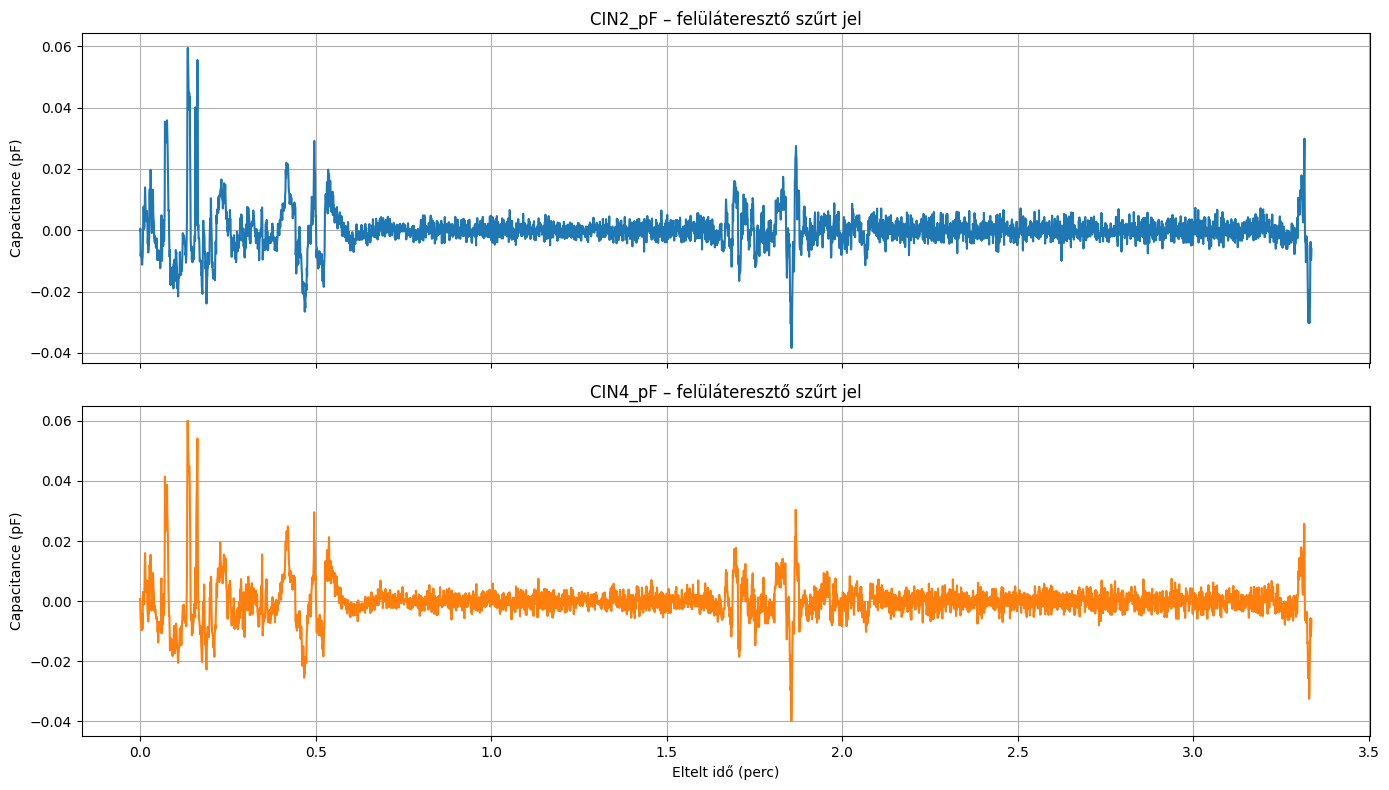

In [2]:
szoritotesz_path = "fdc1004_data_szoritoteszt.csv"
visszateszt_path = "fdc1004_data_visszateszt.csv"
visszateszt_2_path = "fdc1004_data_visszateszt_2.csv"

measurements = {
    "Szorítóteszt": load_data(szoritotesz_path),
    "Visszateszt": load_data(visszateszt_path),
    "Visszateszt 2": load_data(visszateszt_2_path),
}

filtered_sos = {}
capacitance_1_highpass = {}
capacitance_2_highpass = {}

for name, measurement in measurements.items():
    print(name)
    plot_raw_data(measurement)
    filtered_sos[name], capacitance_1_highpass[name], capacitance_2_highpass[name] = plot_filtered_data(
        measurement,
        cutoff_frequency=0.1,
    )


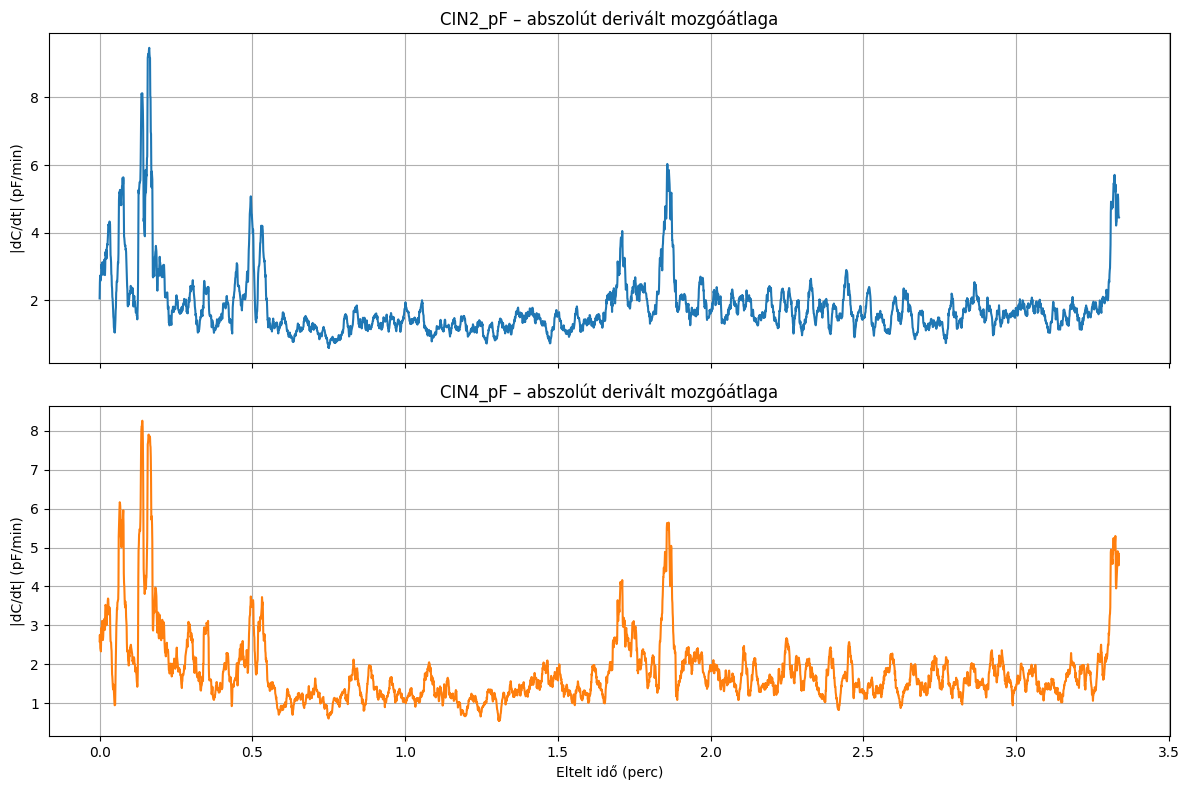

In [5]:
# Moving average of the absolute derivatives of the high-pass filtered signals
moving_average_window = 20

capacitance_1_derivative = np.abs(np.gradient(capacitance_1_highpass["Visszateszt 2"], measurements["Visszateszt 2"].time_min))
capacitance_2_derivative = np.abs(np.gradient(capacitance_2_highpass["Visszateszt 2"], measurements["Visszateszt 2"].time_min))

capacitance_1_derivative_ma = pd.Series(capacitance_1_derivative).rolling(
    window=moving_average_window, center=True, min_periods=1
).mean()
capacitance_2_derivative_ma = pd.Series(capacitance_2_derivative).rolling(
    window=moving_average_window, center=True, min_periods=1
).mean()

fig_derivative_ma, axes_derivative_ma = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes_derivative_ma[0].plot(measurements["Visszateszt 2"].time_min, capacitance_1_derivative_ma, color="tab:blue")
axes_derivative_ma[0].set_ylabel("|dC/dt| (pF/min)")
axes_derivative_ma[0].set_title(f"{measurements["Visszateszt 2"].capacitance_1_key} – abszolút derivált mozgóátlaga")
axes_derivative_ma[0].grid(True)

axes_derivative_ma[1].plot(measurements["Visszateszt 2"].time_min, capacitance_2_derivative_ma, color="tab:orange")
axes_derivative_ma[1].set_xlabel("Eltelt idő (perc)")
axes_derivative_ma[1].set_ylabel("|dC/dt| (pF/min)")
axes_derivative_ma[1].set_title(f"{measurements["Visszateszt 2"].capacitance_2_key} – abszolút derivált mozgóátlaga")
axes_derivative_ma[1].grid(True)

plt.tight_layout()
plt.show()

c:\BME\Szemfedo\CapMeter\MVP_measurements\data_analytics\functions.py:23: DtypeWarning: Columns (0,2) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(file_path)


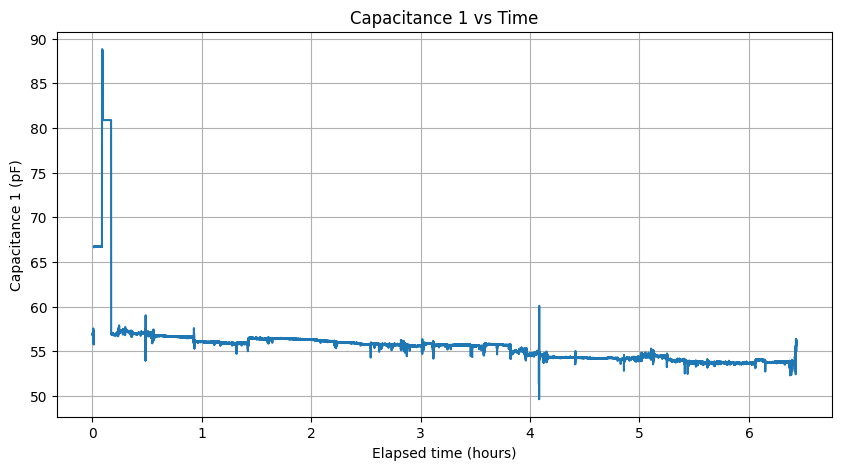

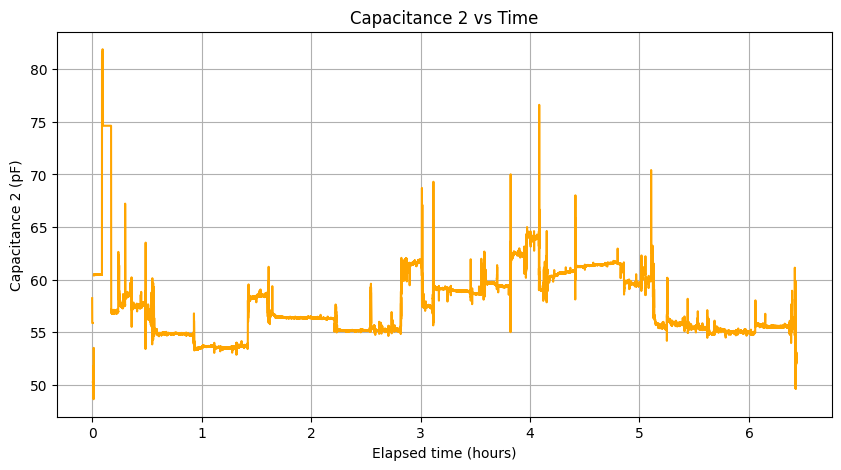

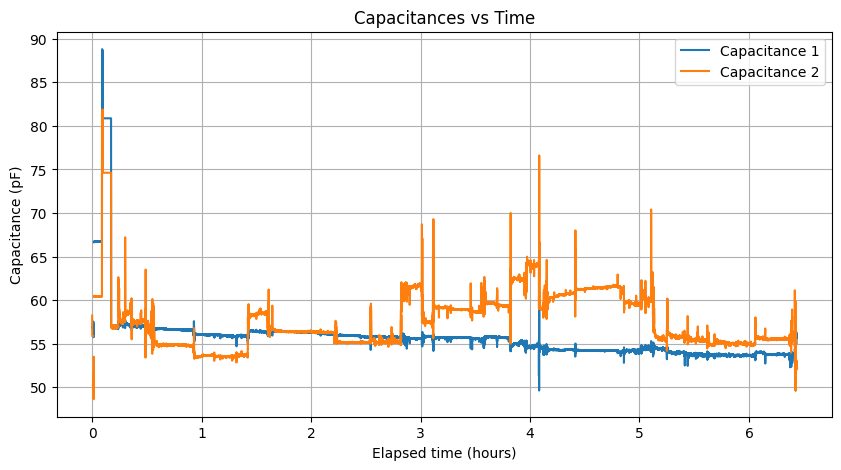

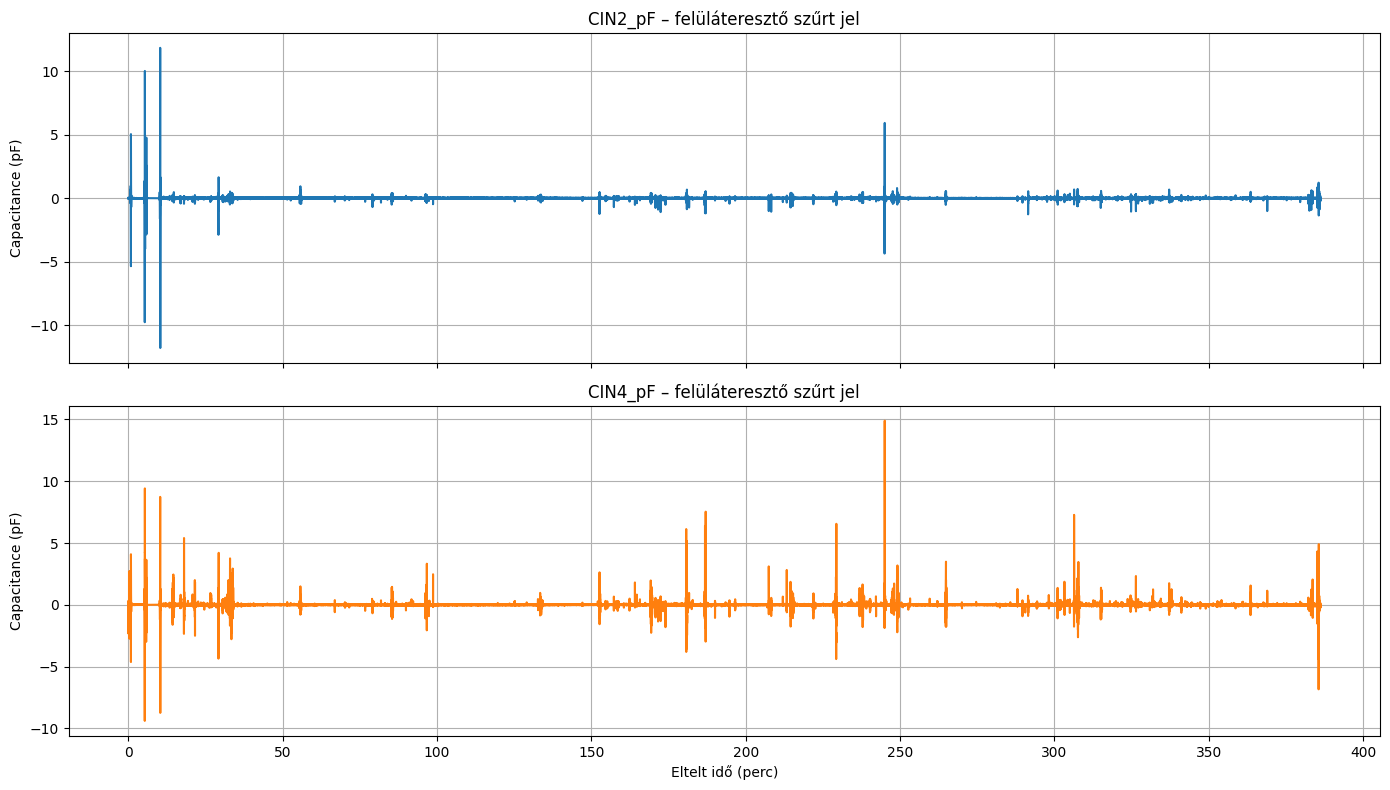

(array([[ 0.95978223, -1.91956446,  0.95978223,  1.        , -1.94263823,
          0.94359728],
        [ 1.        , -2.        ,  1.        ,  1.        , -1.97526963,
          0.97624479]]),
 array([-0.01855013, -0.02683156, -0.0435196 , ..., -0.0347829 ,
        -0.01224351, -0.01514623]),
 array([-1.25408969e-03, -2.31085967e+00, -1.19818186e+00, ...,
        -3.26060157e-02, -3.44831810e-02, -2.40363093e-02]))

In [6]:
second_night_path = "fdc1004_data_2026_10_16.csv"

second_night = load_data(second_night_path)
plot_raw_data(second_night)
plot_filtered_data(second_night, cutoff_frequency=0.1)

c:\BME\Szemfedo\CapMeter\MVP_measurements\data_analytics\functions.py:23: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(file_path)


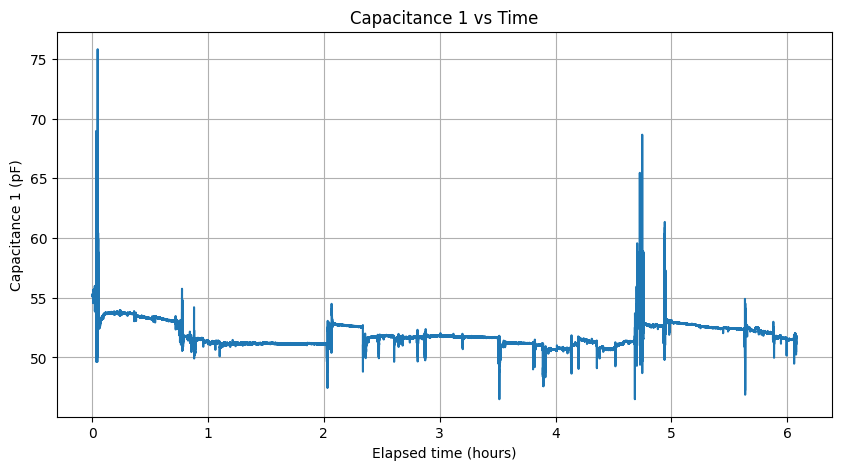

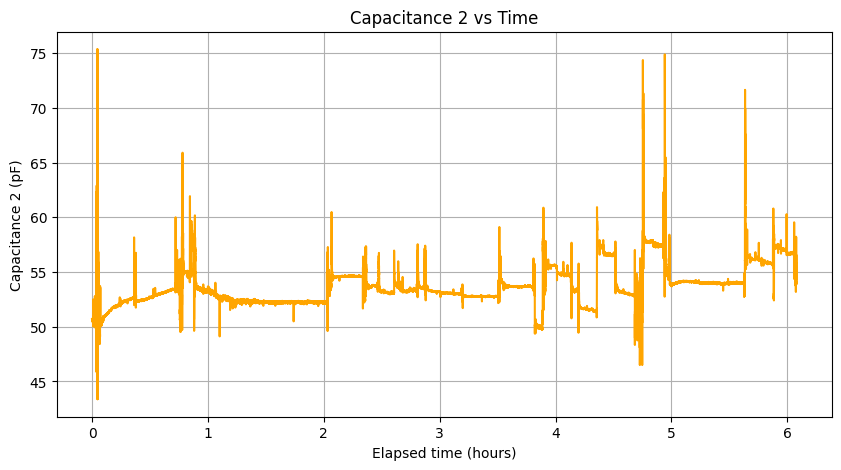

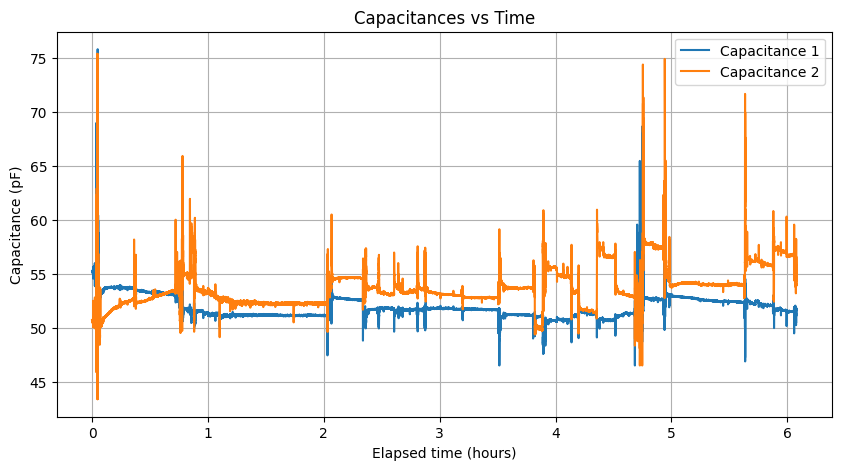

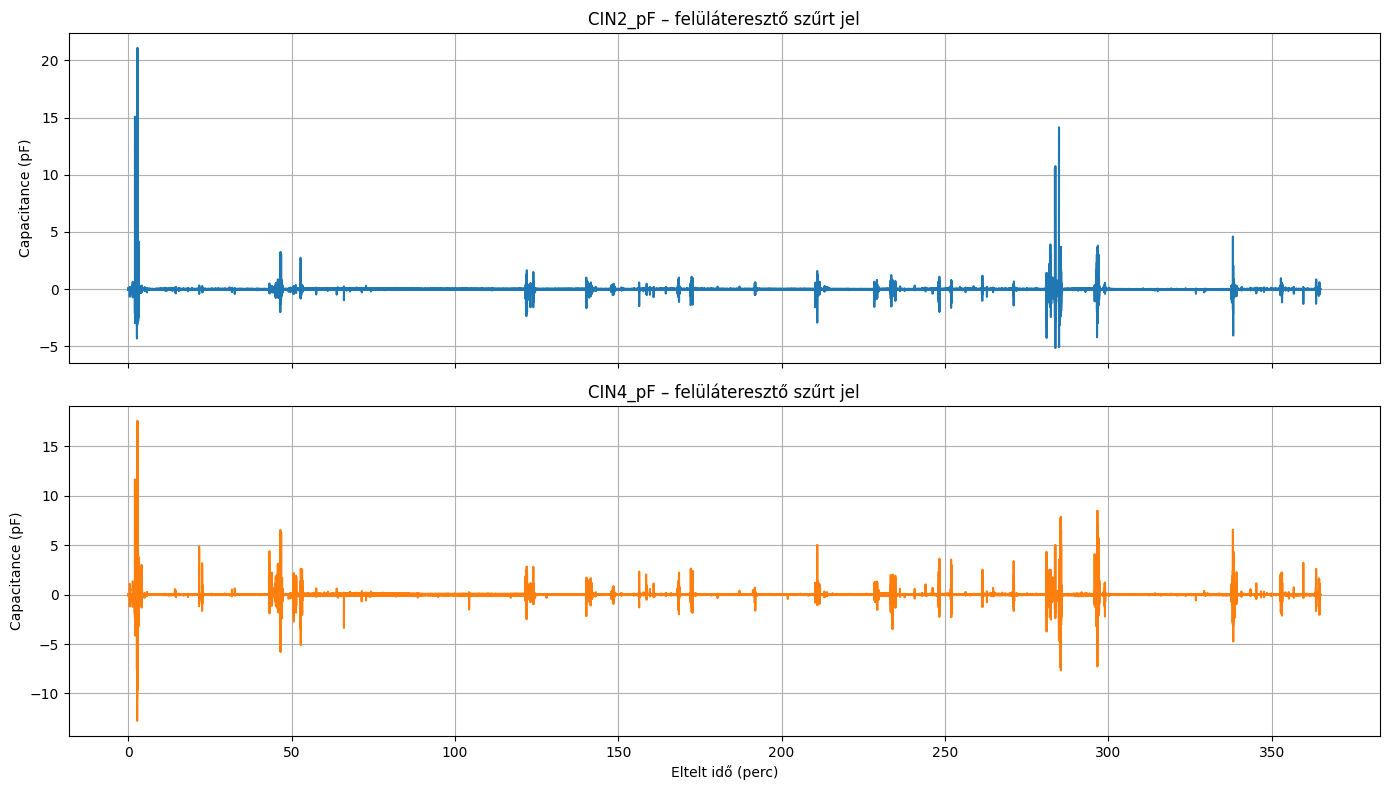

(array([[ 0.95978223, -1.91956446,  0.95978223,  1.        , -1.94263823,
          0.94359728],
        [ 1.        , -2.        ,  1.        ,  1.        , -1.97526963,
          0.97624479]]),
 array([ 0.00295724,  0.00140171, -0.00445754, ...,  0.01447934,
         0.00964379,  0.00664792]),
 array([ 0.00071292,  0.00505549,  0.00471821, ..., -0.00378378,
        -0.01940759, -0.02635907]))

In [3]:
second_night_path = "fdc1004_data_2026_10_17.csv"

second_night = load_data(second_night_path)
plot_raw_data(second_night)
plot_filtered_data(second_night, cutoff_frequency=0.1)